# 3 Forest fires

## 3.1 Forest growth and fire ignition

<div style="background-color:#f0f8ff;border:2px solid #4682b4;padding:10px;">
    
<strong>Note:</strong> This notebook contains the code for sections 3.1 from the book  

**Simulation of Complex Systems**  
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)

You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)

</div>

**Seminal references:** Bak, Tang & Wiesenfeld (1987), *Self-organized criticality: an explanation of 1/f noise*, Phys. Rev. Lett. **59**, 381; Drossel & Schwabl (1992), *Self-organized critical forest-fire model*, Phys. Rev. Lett. **69**, 1629. See also the textbook's Chapter 3 references.

<a id="model"></a>
**Model** 

$N \times N$ Boolean lattice, initially empty. 

Tree growth probability: $p$. 

Lightning strike probability $f$.

When lightning ignites a tree, it expands to the complete connected cluster of neighbors within a single time step. 

Neighborhood: von Neumann.

Periodic boundary conditions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

N = 16
p = 0.01
f = 0.2
forest = np.zeros((N, N), dtype=bool)

<a id="growth"></a>
Let's make trees grow (one turn)

In [2]:
forest0 = forest.copy()

forest |= np.random.random((N, N)) < p

Let's plot the forest

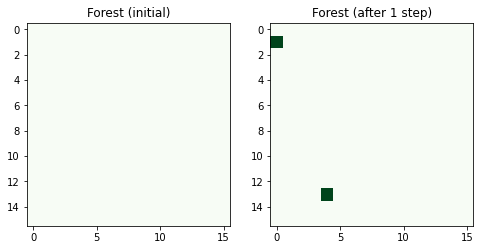

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(forest0, cmap="Greens", vmin=0, vmax=1)
ax[0].set_title("Forest (initial)")
ax[1].imshow(forest, cmap="Greens", vmin=0, vmax=1)
ax[1].set_title("Forest (after 1 step)")
plt.show()

Let's check whether a lightning occurs.

In [4]:
lightning = None
if np.random.random() < f:
    lightning = (np.random.randint(N), np.random.randint(N))
print("Lightning target:", lightning)

Lightning target: None


Let's assume that one lightning occurred and ignited one of the trees in the forest.

We higlight the 4 cells in its neighborhood (von Neuman neighborhood) that can be ignited by the fire.

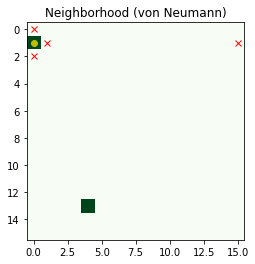

In [5]:
# we pick one of the tree-populated cells
n_trees = np.sum(forest)
assert n_trees > 0, "The forest contains no trees"

chosen = np.random.randint(n_trees)
i, j = np.argwhere(forest)[chosen] 

# periodic boundary conditions
i_neighbors = np.array([i + 1, i - 1]) % N
j_neighbors = np.array([j + 1, j - 1]) % N

# plot
plt.imshow(forest, cmap="Greens", vmin=0, vmax=1)
plt.plot(j, i, "yo")
plt.plot(j_neighbors, [i, i], "rx")
plt.plot([j, j], i_neighbors, "rx")
        
plt.title("Neighborhood (von Neumann)")
plt.show()

Let's see how to tell where the fire could spread.

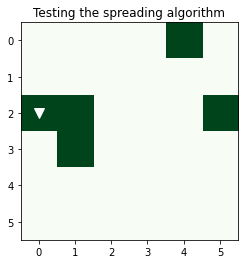

In [6]:
example = np.zeros((6, 6), dtype=bool)
example[2, [0, 1, 5]] = True
example[3, 1] = True
example[0, 4] = True
start = (2, 0)
plt.imshow(example, cmap="Greens", vmin=0, vmax=1)
plt.plot(start[1], start[0], 'wv', markersize=10)  # ignition site
plt.title("Testing the spreading algorithm")
plt.show()

<a id="fire-spreading"></a>

Let's implement the spreading of the fire.

In [7]:
visited = np.zeros_like(example)
stack = [start]
visited[start] = True
cluster = []

In [8]:
while stack:
    row, col = stack.pop()
    cluster.append((row, col))
    neighbors = [((row - 1) % 6, col), ((row + 1) % 6, col),
                 (row, (col - 1) % 6), (row, (col + 1) % 6)]
    for r, c in neighbors:
        if example[r, c] and not visited[r, c]:
            visited[r, c] = True
            stack.append((r, c))
print("Burned cluster:", cluster)

example_before_fire = example.copy()

for row, col in cluster:
    example[row, col] = False
print("Trees left after this fire:", example.sum())

Burned cluster: [(2, 0), (2, 1), (3, 1), (2, 5)]
Trees left after this fire: 1


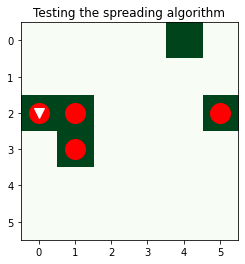

In [9]:
# let's plot the burned cluster
plt.imshow(example_before_fire, cmap="Greens", vmin=0, vmax=1)
for n in range(len(cluster)):
    plt.plot(
        cluster[n][1], 
        cluster[n][0], 
        'ro',
        markersize=20
    )  # burned site
plt.plot(start[1], start[0], 'wv', markersize=10)  # ignition site
plt.title("Testing the spreading algorithm")
plt.show()

<a id="implementation"></a>
Let's implement the model.

Initialization:

In [10]:
N = 32
p = 0.01
f = 0.2

forest = np.zeros((N, N), dtype=bool)
fire_sizes = []
density_history = []

steps = 400

Iterations:

In [11]:
for t in range(steps):
    forest |= np.random.random((N, N)) < p
    density_history.append(forest.mean())
    if np.random.random() < f:
        target = (
            np.random.randint(N), np.random.randint(N)
        )
        if forest[target]:
            visited = np.zeros_like(forest)
            visited[target] = True
            stack = [target]
            burned = []
            while stack:
                row, col = stack.pop()
                burned.append((row, col))
                for r, c in [
                    ((row-1) % N, col), 
                    ((row+1) % N, col), 
                    (row, (col-1) % N), 
                    (row, (col+1) % N)
                ]:
                    if forest[r, c] and not visited[r, c]:
                        visited[r, c] = True
                        stack.append((r, c))
            for row, col in burned:
                forest[row, col] = False
            fire_sizes.append(len(burned))

Let's plot the forest after `steps` steps.

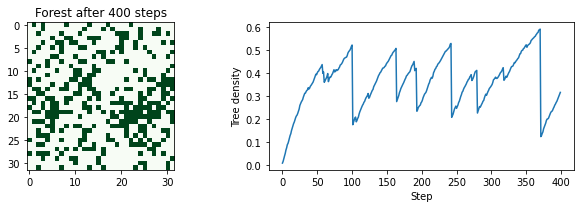

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].imshow(forest, cmap="Greens", vmin=0, vmax=1)
axes[0].set_title(f"Forest after {steps} steps")
axes[1].plot(density_history)
axes[1].set(
    xlabel="Step", 
    ylabel="Tree density"
)
plt.tight_layout()
plt.show()

<a id="animation"></a>
Let's animate the process.

Importing packages

In [13]:
try:
    import pygame
except ImportError:
    %pip -q install pygame
    import pygame
import io
import ipywidgets as widgets
from IPython.display import display
from PIL import Image

pygame 2.5.2 (SDL 2.28.3, Python 3.8.5)
Hello from the pygame community. https://www.pygame.org/contribute.html


Importing the modules

In [14]:
import sys
from pathlib import Path
module_dir = str(Path.cwd().resolve().parent / "03_modules")
if module_dir not in sys.path:
    sys.path.insert(0, module_dir)
import forest_fires as ff
import forest_visualize as fv

Initialization.

In [15]:
Nx = 240
Ny = 180
p = 0.01
f = 0.2

forest = np.zeros((Ny, Nx), dtype=bool)

Animation.

In [16]:
# prepare the window for the animation
image_widget = widgets.Image(
    format="png", 
    width=Nx, 
    height=Ny
)
label = widgets.Label(value="Step: 0")
display(widgets.VBox([label, image_widget]))


# iterations
frames = 800
nskip = 1

for frame in range(frames):
    burned = []
    lightning = None
    for _ in range(nskip):
        forest, size, lightning, burned = ff.step(forest, p, f)
        
    image_widget.value = fv.png_frame(
        forest, 
        width=200, 
        burned=burned, 
        lightning=lightning
    )
    
    label.value = (
        f"Step: {(frame + 1)*nskip} | "
        f"density: {forest.mean():.2f} | "
        f"last fire: {len(burned)}"
    )

<a id="questions"></a>
## Questions

Here you find the questions:

- [Q1: Independent growth](#q1)
- [Q2: Lightning and ignition](#q2)
- [Q3: Implementation](#q3)
- [Q4: Animation](#q4)

<a id="q1"></a>
**Q1: Independent growth**

Refer to [model](#model) and [growth](#growth).

[Go back to questions](#questions)

Consider the line:
```python
forest |= np.random.random((N, N)) < p
```
which is the implementation of the growing step in the model.

a. You substitute it with the lines:
```python
empty = ~forest
growth_draws = np.random.random((N, N))
new_trees = empty & (growth_draws < p)
forest[new_trees] = True
```
Is this a correct implementation of the growing step? Why or why not?

b.You substitute it with the line:
```python
forest = np.random.random((N, N)) < p
```
Is this a correct implementation of the growing step? Why or why not?


c. You substitute it with the lines:
```python
growth = np.random.random((N, N)) < p
forest[growth] = True
```
Is this a correct implementation of the growing step? Why or why not?

<a id="q2"></a>
**Q2: Lightning and ignition.**

Refer to [the spreading of fire](#fire-spreading).

[Go back to questions](#questions)

Review the example of the fire-spreading algorithm. `stack` is a list of tuples. <br> 
Suppose that:
```python
stack = [(2, 1), (1, 2), (2, 3), (3, 2)]
```
and you execute the line: 
```python
row, col = stack.pop()
```
After executing this line:

a. What is the value of `row`?

b. What is the value of `col`?

c. What is the value of `stack`?


<a id="q3"></a>
**Q3: Implementation.**

Refer to [implementation](#implementation).

[Go back to questions](#questions)

a. We consider a forest with closed boundaries (i.e, no periodic boundary conditions). Explain how you would implement this. Show which part of the code needs modification.

b. We allow the fire to also spread to the diagonal cells (i.e., in a Moore's neighborhood setting). Explain how you would implement this. Show which part of the code needs modification.

c. Observe the graph "Tree density vs. Step". Can you explain its *sawtooth* appearance? Why is each period of steadily increasing tree density followed by an abrupt drop?


<a id="q4"></a>
**Q4: Animation.**

Refer to [animation](#animation) and the [visualization module](../03_modules/forest_visualize.py).

[Go back to questions](#questions)

In the module, check the function `png_frame` . It includes the following lines:
```python
    for row, col in np.argwhere(forest):
        pygame.draw.rect(
            surface, 
            forest_col,
            (int(col * scale), int(row * scale), 
             scale, scale)
        )
```

a. Suppose that:
```python
forest = [[True, False], [True, False]]
``` 
what is the outcome of `np.argwhere(forest)` ?  

b. Suppose that:
```python
forest = [[True, True], [True, False]]
``` 
how many iterations will the `for` cycle do?

c. Explain the purpose of the `for` loop above. What does it do?

